# Predição de Evasão e Sucesso Acadêmico — Grupo 7

**BSI — Inteligência de Negócios — 2026-2 · Trabalho prático de Mineração de Dados**

Base: [Predict Students' Dropout and Academic Success](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) (UCI, id 697).

Classificadores: **KNN, SVM, Random Forest e XGBoost**.

Protocolo experimental:
- divisão estratificada **80% treino / 20% teste** (`random_state=42`);
- ajuste de hiperparâmetros com **validação cruzada estratificada de 5 partições** no conjunto de treino, usando **as mesmas partições** para todos os classificadores;
- critério de seleção: **F1 macro** (a base é desbalanceada);
- métricas finais (acurácia, precisão, revocação, F1 e matriz de confusão) calculadas no conjunto de teste, que não é usado em nenhuma etapa de ajuste.

Todo o pré-processamento que aprende parâmetros dos dados (one-hot e normalização) fica **dentro do `Pipeline`**, para não vazar informação entre as partições.

## 1. Setup

As dependências estão em `requirements.txt` (`pip install -r requirements.txt`).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

RANDOM_STATE = 42

FIG_DIR = Path('figuras')
RES_DIR = Path('resultados')
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', None)
pd.set_option('display.float_format', '{:.4f}'.format)

# Paleta categórica (ordem fixa, validada para daltonismo) e estilo dos gráficos
CORES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100']
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.color': '#e4e3df',
    'grid.linewidth': 0.8,
    'axes.axisbelow': True,
    'axes.edgecolor': '#8a8984',
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'legend.frameon': False,
})


def salvar_fig(fig, nome):
    # Salva a figura em figuras/<nome>.png para uso no artigo.
    fig.savefig(FIG_DIR / f'{nome}.png', dpi=200, bbox_inches='tight')

In [2]:
dataset = fetch_ucirepo(id=697)

X = dataset.data.features.copy()
y = dataset.data.targets.squeeze()   # alvo em 1D (Series), evita o DataConversionWarning

print('X:', X.shape, '| y:', y.shape)

X: (4424, 36) | y: (4424,)


## 2. Análise exploratória

### 2.1 Registros, atributos e tipos

In [3]:
print(f'Registros: {X.shape[0]} | Atributos preditivos: {X.shape[1]} | Variável-alvo: {y.name}')

tipos = dataset.variables[['name', 'role', 'type', 'demographic']].set_index('name')
tipos['dtype_pandas'] = pd.concat([X, y], axis=1).dtypes.astype(str)
tipos

Registros: 4424 | Atributos preditivos: 36 | Variável-alvo: Target


,role,type,demographic,dtype_pandas
name,,,,
Marital Status,Feature,Integer,Marital Status,int64
Application mode,Feature,Integer,NaN,int64
Application order,Feature,Integer,NaN,int64
Course,Feature,Integer,NaN,int64
Daytime/evening attendance,Feature,Integer,NaN,int64
Previous qualification,Feature,Integer,Education Level,int64
Previous qualification (grade),Feature,Continuous,NaN,float64
Nacionality,Feature,Integer,Nationality,int64
Mother's qualification,Feature,Integer,Education Level,int64


In [4]:
X.describe().T[['mean', 'std', 'min', '50%', 'max']]

,mean,std,min,50%,max
Marital Status,1.1786,0.6057,1.0000,1.0000,6.0000
Application mode,18.6691,17.4847,1.0000,17.0000,57.0000
Application order,1.7278,1.3138,0.0000,1.0000,9.0000
Course,8856.6426,2063.5664,33.0000,9238.0000,9991.0000
Daytime/evening attendance,0.8908,0.3119,0.0000,1.0000,1.0000
Previous qualification,4.5778,10.2166,1.0000,1.0000,43.0000
Previous qualification (grade),132.6133,13.1883,95.0000,133.1000,190.0000
Nacionality,1.8732,6.9145,1.0000,1.0000,109.0000
Mother's qualification,19.5619,15.6032,1.0000,19.0000,44.0000
Father's qualification,22.2753,15.3431,1.0000,19.0000,44.0000


Todos os 36 atributos são numéricos no arquivo, mas vários deles são **categóricos nominais codificados como inteiros**
(ex.: `Course` = 9500 não é "maior" que `Course` = 171). Há também atributos binários (0/1) e atributos numéricos contínuos ou de contagem.
A classificação usada no pré-processamento está na seção 3.3.

Observação: os metadados da UCI marcam as notas semestrais (`Curricular units ... (grade)`) como *Integer*, mas os valores são contínuos (`float64`), na escala de 0 a 20.

### 2.2 Variável-alvo

In [5]:
y.value_counts()

Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64

A variável-alvo é **`Target`**, com três classes que descrevem a situação do estudante ao final do prazo normal do curso:

| Classe | Significado |
|---|---|
| **Dropout** | o estudante evadiu (abandonou o curso) |
| **Enrolled** | o estudante continua matriculado após o prazo normal de conclusão |
| **Graduate** | o estudante concluiu o curso |

### 2.3 Valores ausentes e duplicados

In [6]:
print('Valores ausentes nos atributos:', int(X.isna().sum().sum()))
print('Valores ausentes no alvo      :', int(y.isna().sum()))
print('Registros duplicados (X + y)  :', int(pd.concat([X, y], axis=1).duplicated().sum()))
print('Registros duplicados (só X)   :', int(X.duplicated().sum()))

Valores ausentes nos atributos: 0
Valores ausentes no alvo      : 0
Registros duplicados (X + y)  : 0
Registros duplicados (só X)   : 0


### 2.4 Inconsistências

In [7]:
def cu(semestre, campo):
    return f'Curricular units {semestre} sem ({campo})'


regras = {}
for s in ['1st', '2nd']:
    regras[f'Aprovadas > matriculadas ({s} sem)'] = (X[cu(s, 'approved')] > X[cu(s, 'enrolled')]).sum()
    regras[f'Aprovadas > avaliações ({s} sem)'] = (X[cu(s, 'approved')] > X[cu(s, 'evaluations')]).sum()
    regras[f'Nota fora de [0, 20] ({s} sem)'] = (~X[cu(s, 'grade')].between(0, 20)).sum()
    regras[f'Nota > 0 sem aprovações ({s} sem)'] = ((X[cu(s, 'grade')] > 0) & (X[cu(s, 'approved')] == 0)).sum()
    regras[f'Nota = 0 com aprovações ({s} sem)'] = ((X[cu(s, 'grade')] == 0) & (X[cu(s, 'approved')] > 0)).sum()
regras['Nota de admissão fora de [0, 200]'] = (~X['Admission grade'].between(0, 200)).sum()
regras['Nota da qualificação anterior fora de [0, 200]'] = (~X['Previous qualification (grade)'].between(0, 200)).sum()
regras['Idade de ingresso < 15'] = (X['Age at enrollment'] < 15).sum()
regras['Contagens negativas'] = (X.filter(like='Curricular units').drop(columns=[cu('1st', 'grade'), cu('2nd', 'grade')]) < 0).sum().sum()

pd.Series(regras, name='Ocorrências').to_frame()

,Ocorrências
Aprovadas > matriculadas (1st sem),0
Aprovadas > avaliações (1st sem),0
"Nota fora de [0, 20] (1st sem)",0
Nota > 0 sem aprovações (1st sem),0
Nota = 0 com aprovações (1st sem),0
Aprovadas > matriculadas (2nd sem),0
Aprovadas > avaliações (2nd sem),0
"Nota fora de [0, 20] (2nd sem)",0
Nota > 0 sem aprovações (2nd sem),0
Nota = 0 com aprovações (2nd sem),0


In [8]:
sem_matricula = (X[cu('1st', 'enrolled')] == 0) & (X[cu('2nd', 'enrolled')] == 0)
print('Estudantes sem unidades curriculares matriculadas nos dois semestres:', int(sem_matricula.sum()))
y[sem_matricula].value_counts()

Estudantes sem unidades curriculares matriculadas nos dois semestres: 180


Target
Dropout     77
Graduate    75
Enrolled    28
Name: count, dtype: int64

Nenhuma regra de consistência foi violada. Dois pontos merecem registro:

- A nota semestral corresponde à média das unidades **aprovadas**: ela vale 0 exatamente quando não há aprovações, então o zero é um valor válido e não um dado ausente.
- Há **180** estudantes sem unidades matriculadas nos dois semestres, e boa parte deles concluiu o curso. Isso é compatível com estudantes que tiveram as disciplinas **creditadas** (aproveitamento de estudos), por isso os registros foram mantidos.

As idades vão de 17 a 70 anos (poucos casos acima de 60), o que é plausível para ingresso no ensino superior.

### 2.5 Distribuição da variável-alvo

,Quantidade,Proporção (%)
Target,,
Graduate,2209,49.9322
Dropout,1421,32.1203
Enrolled,794,17.9476


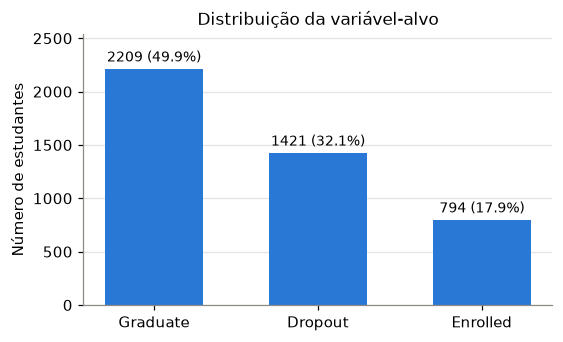

In [9]:
dist = pd.DataFrame({'Quantidade': y.value_counts(), 'Proporção (%)': y.value_counts(normalize=True) * 100})
dist.to_csv(RES_DIR / 'distribuicao_alvo.csv')
display(dist)

fig, ax = plt.subplots(figsize=(5.5, 3.2))
barras = ax.bar(dist.index, dist['Quantidade'], color=CORES[0], width=0.6)
for barra, (qtd, pct) in zip(barras, dist.values):
    ax.annotate(f'{qtd:.0f} ({pct:.1f}%)', (barra.get_x() + barra.get_width() / 2, qtd),
                ha='center', va='bottom', fontsize=9, xytext=(0, 3), textcoords='offset points')
ax.set_ylabel('Número de estudantes')
ax.set_title('Distribuição da variável-alvo')
ax.grid(axis='x', visible=False)
ax.set_ylim(0, dist['Quantidade'].max() * 1.15)
salvar_fig(fig, 'distribuicao_alvo')
plt.show()

A base é **desbalanceada**: *Graduate* corresponde a cerca de metade dos registros, enquanto *Enrolled* tem menos de 18%.
Por isso:
- a divisão treino/teste e as partições da validação cruzada são **estratificadas**;
- o critério de seleção dos modelos é o **F1 macro**, que dá o mesmo peso às três classes (a acurácia favoreceria a classe majoritária);
- `class_weight='balanced'` (SVM e Random Forest) e `sample_weight` balanceado (XGBoost) são testados como configurações.

### 2.6 Atributos relevantes versus alvo

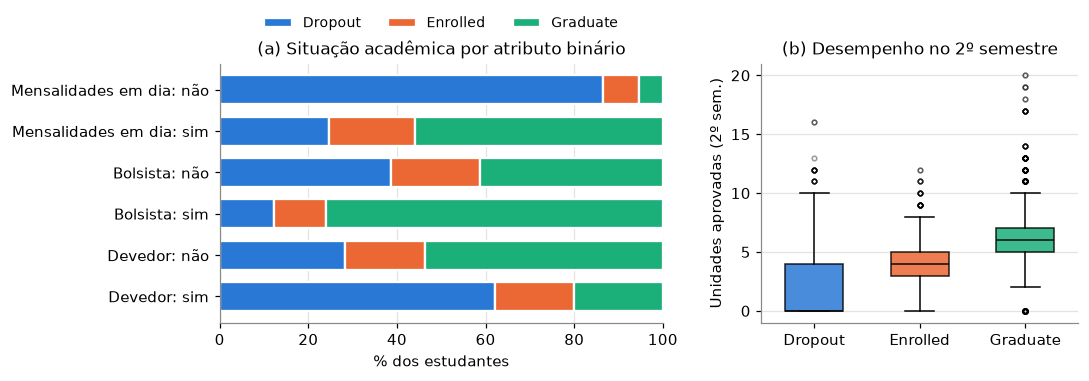

In [10]:
CLASSES_ORDEM = ['Dropout', 'Enrolled', 'Graduate']
COR_CLASSE = dict(zip(CLASSES_ORDEM, CORES))

binarios = {'Tuition fees up to date': 'Mensalidades em dia', 'Scholarship holder': 'Bolsista', 'Debtor': 'Devedor'}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={'width_ratios': [1.4, 1]})

# (a) proporção das classes por atributo binário
ax = axes[0]
linhas, rotulos = [], []
for col, nome in binarios.items():
    for valor, txt in [(0, 'não'), (1, 'sim')]:
        linhas.append(y[X[col] == valor].value_counts(normalize=True).reindex(CLASSES_ORDEM))
        rotulos.append(f'{nome}: {txt}')
prop = pd.DataFrame(linhas, index=rotulos) * 100
esquerda = np.zeros(len(prop))
for classe in CLASSES_ORDEM:
    ax.barh(prop.index, prop[classe], left=esquerda, color=COR_CLASSE[classe], label=classe,
            edgecolor='white', linewidth=1.5, height=0.7)
    esquerda += prop[classe].values
ax.invert_yaxis()
ax.set_xlabel('% dos estudantes')
ax.set_xlim(0, 100)
ax.grid(axis='y', visible=False)
ax.set_title('(a) Situação acadêmica por atributo binário')
ax.legend(ncol=3, loc='lower center', bbox_to_anchor=(0.5, 1.08), fontsize=9)

# (b) unidades aprovadas no 2º semestre por classe
ax = axes[1]
dados = [X.loc[y == c, cu('2nd', 'approved')] for c in CLASSES_ORDEM]
bp = ax.boxplot(dados, tick_labels=CLASSES_ORDEM, patch_artist=True, widths=0.55,
                medianprops={'color': '#0b0b0b'}, flierprops={'markersize': 3, 'alpha': 0.4})
for patch, classe in zip(bp['boxes'], CLASSES_ORDEM):
    patch.set_facecolor(COR_CLASSE[classe])
    patch.set_alpha(0.85)
ax.set_ylabel('Unidades aprovadas (2º sem.)')
ax.grid(axis='x', visible=False)
ax.set_title('(b) Desempenho no 2º semestre')

fig.tight_layout()
salvar_fig(fig, 'atributos_vs_alvo')
plt.show()

Os gráficos indicam atributos com forte relação com a evasão: estudantes **com mensalidades atrasadas** ou **devedores** têm proporção de evasão muito maior,
enquanto **bolsistas** evadem menos. O número de **unidades aprovadas no 2º semestre** separa bem *Dropout* das demais classes,
mas *Enrolled* fica em posição intermediária e se sobrepõe às outras duas, o que antecipa a dificuldade em classificá-la.

## 3. Pré-processamento

### 3.1 Valores ausentes, duplicados e inconsistências

Conforme as seções 2.3 e 2.4, a base **não tem valores ausentes, registros duplicados nem violações das regras de consistência**,
então nenhum registro foi removido ou imputado. Os zeros nas notas semestrais e os estudantes sem unidades matriculadas foram mantidos por serem valores válidos no domínio.

### 3.2 Identificadores e atributos não preditivos

In [11]:
candidatos_id = [c for c in X.columns if X[c].nunique() == len(X)]
print('Colunas com um valor distinto por registro (possíveis identificadores):', candidatos_id or 'nenhuma')

Colunas com um valor distinto por registro (possíveis identificadores): nenhuma


A base **não contém identificadores** (código de matrícula, nome etc.): nenhuma coluna tem um valor distinto por registro,
e todos os atributos descrevem características do estudante, do seu desempenho ou do contexto socioeconômico. Por isso, nenhum atributo foi removido.

### 3.3 Tipos de atributos

In [12]:
COLS_NOMINAIS = [
    'Marital Status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality',
    "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation",
]
COLS_BINARIAS = [
    'Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor',
    'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International',
]
COLS_NUMERICAS = [c for c in X.columns if c not in COLS_NOMINAIS + COLS_BINARIAS]

assert len(COLS_NOMINAIS) + len(COLS_BINARIAS) + len(COLS_NUMERICAS) == X.shape[1]

print(f'Nominais ({len(COLS_NOMINAIS)}):', COLS_NOMINAIS, '\n')
print(f'Binárias ({len(COLS_BINARIAS)}):', COLS_BINARIAS, '\n')
print(f'Numéricas ({len(COLS_NUMERICAS)}):', COLS_NUMERICAS)
X[COLS_NOMINAIS].nunique().rename('Categorias distintas').to_frame()

Nominais (9): ['Marital Status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"] 

Binárias (8): ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'] 

Numéricas (19): ['Application order', 'Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate'

,Categorias distintas
Marital Status,6
Application mode,18
Course,17
Previous qualification,17
Nacionality,21
Mother's qualification,29
Father's qualification,34
Mother's occupation,32
Father's occupation,46


`Application order` (ordem de preferência da candidatura, de 0 a 9) é ordinal e foi tratada como numérica.

### 3.4 Codificação da variável-alvo

In [13]:
le = LabelEncoder()
y_cod = le.fit_transform(y)
CLASSES = list(le.classes_)
print(dict(zip(CLASSES, range(len(CLASSES)))))

{'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}


O alvo é codificado uma única vez (0 = Dropout, 1 = Enrolled, 2 = Graduate) e usado por todos os modelos, porque o XGBoost exige rótulos numéricos.
Os nomes originais (`CLASSES`) são usados nos relatórios e nas matrizes de confusão.

### 3.5 Preprocessador comum

In [14]:
MIN_FREQ = 20  # categorias com menos de 20 ocorrências no treino viram uma categoria "infrequente"


def criar_preprocessador():
    return ColumnTransformer([
        ('nom', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=MIN_FREQ,
                              sparse_output=False), COLS_NOMINAIS),
        ('num', StandardScaler(), COLS_NUMERICAS),
        ('bin', 'passthrough', COLS_BINARIAS),
    ])

- **Nominais** → *one-hot encoding*. As categorias raras (menos de 20 ocorrências no treino) são agrupadas em uma categoria "infrequente", para limitar a dimensionalidade, e categorias nunca vistas também caem nela.
- **Numéricas** → padronização (`StandardScaler`, média 0 e desvio 1), essencial para os modelos baseados em distância (KNN) e margem (SVM).
- **Binárias** → mantidas como 0/1.

O preprocessador só é ajustado dentro do `Pipeline` de cada modelo, ou seja, apenas com os dados de treino de cada partição.

## 4. Divisão dos dados e utilitários

### 4.1 Treino e teste

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y_cod, test_size=0.2, stratify=y_cod, random_state=RANDOM_STATE
)

print(f'Treino: {len(X_train)} registros | Teste: {len(X_test)} registros')
pd.DataFrame({
    'Treino (%)': pd.Series(y_train).value_counts(normalize=True).sort_index().values * 100,
    'Teste (%)': pd.Series(y_test).value_counts(normalize=True).sort_index().values * 100,
}, index=CLASSES)

Treino: 3539 registros | Teste: 885 registros


,Treino (%),Teste (%)
Dropout,32.1277,32.0904
Enrolled,17.9429,17.9661
Graduate,49.9294,49.9435


In [16]:
dim = criar_preprocessador().fit(X_train).get_feature_names_out()
print(f'Dimensão após o pré-processamento: {len(dim)} atributos (de {X.shape[1]} originais)')

Dimensão após o pré-processamento: 119 atributos (de 36 originais)


### 4.2 Partições da validação cruzada (compartilhadas)

In [17]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# As mesmas 5 partições são usadas por todos os GridSearchCV
for i, (tr, va) in enumerate(cv.split(X_train, y_train), 1):
    print(f'Partição {i}: treino={len(tr)}  validação={len(va)}')

Partição 1: treino=2831  validação=708
Partição 2: treino=2831  validação=708
Partição 3: treino=2831  validação=708
Partição 4: treino=2831  validação=708
Partição 5: treino=2832  validação=707


### 4.3 Busca de hiperparâmetros

In [18]:
SCORING = {
    'accuracy': 'accuracy',
    'precision_macro': 'precision_macro',
    'recall_macro': 'recall_macro',
    'f1_macro': 'f1_macro',
}


def buscar(classificador, grid, **fit_params):
    # GridSearchCV padrão: preprocessador comum + classificador, mesmas partições, refit pelo F1 macro.
    pipe = Pipeline([('prep', criar_preprocessador()), ('classifier', classificador)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring=SCORING, refit='f1_macro', n_jobs=-1)
    gs.fit(X_train, y_train, **fit_params)
    print(f'{len(gs.cv_results_["params"])} configurações x 5 partições')
    print('Melhores parâmetros:', formatar_params(gs.best_params_))
    print(f'F1 macro (CV): {gs.best_score_:.4f}')
    return gs


def formatar_params(params):
    return ', '.join(f"{k.replace('classifier__', '')}={v}" for k, v in params.items())

### 4.4 Avaliação no conjunto de teste

In [19]:
RESULTADOS_TESTE = {}
MATRIZES = {}
PREDICOES = {}


def avaliar(modelo, nome):
    y_pred = modelo.predict(X_test)
    metricas = {
        'Acurácia': accuracy_score(y_test, y_pred),
        'Precisão (macro)': precision_score(y_test, y_pred, average='macro'),
        'Revocação (macro)': recall_score(y_test, y_pred, average='macro'),
        'F1 (macro)': f1_score(y_test, y_pred, average='macro'),
    }
    for classe, f1 in zip(CLASSES, f1_score(y_test, y_pred, average=None)):
        metricas[f'F1 {classe}'] = f1

    print(f'=== {nome} — conjunto de teste ===')
    print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

    cm = confusion_matrix(y_test, y_pred)
    fig, ax = plt.subplots(figsize=(4.2, 3.8))
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.grid(False)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real')
    ax.set_title(f'Matriz de confusão — {nome}')
    salvar_fig(fig, f'matriz_confusao_{SLUG[nome]}')
    plt.show()

    RESULTADOS_TESTE[nome] = metricas
    MATRIZES[nome] = cm
    PREDICOES[nome] = y_pred
    return metricas


SLUG = {'KNN': 'knn', 'SVM': 'svm', 'Random Forest': 'random_forest', 'XGBoost': 'xgboost'}

### 4.5 Tabela de resultados da validação cruzada

In [20]:
TABELAS_CV = {}
ROTULOS_METRICAS = {'accuracy': 'Acurácia', 'precision_macro': 'Precisão', 'recall_macro': 'Revocação', 'f1_macro': 'F1 macro'}


def tabela_cv(gs, nome, balanceado=None):
    # Converte cv_results_ em DataFrame (média e desvio de cada métrica).
    # balanceado: força o valor da coluna 'Balanceamento' (usado no XGBoost, cujo peso vai no fit).
    r = gs.cv_results_
    tab = pd.DataFrame({
        'Modelo': nome,
        'Configuração': [formatar_params(p) for p in r['params']],
        'Balanceamento': [balanceado if balanceado is not None else p.get('classifier__class_weight') == 'balanced'
                          for p in r['params']],
    })
    for m, rot in ROTULOS_METRICAS.items():
        tab[f'{rot} (média)'] = r[f'mean_test_{m}']
        tab[f'{rot} (dp)'] = r[f'std_test_{m}']
    tab['Tempo de ajuste (s)'] = r['mean_fit_time']
    tab = tab.sort_values('F1 macro (média)', ascending=False).reset_index(drop=True)
    tab.to_csv(RES_DIR / f'cv_{SLUG.get(nome, nome)}.csv', index=False)
    return tab

## 5. K-Nearest Neighbors (KNN)

In [21]:
grid_knn = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15, 21],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan'],
}

gs_knn = buscar(KNeighborsClassifier(), grid_knn)
TABELAS_CV['KNN'] = tabela_cv(gs_knn, 'KNN')
TABELAS_CV['KNN'].head(10)

28 configurações x 5 partições
Melhores parâmetros: metric=manhattan, n_neighbors=7, weights=uniform
F1 macro (CV): 0.6282


,Modelo,Configuração,Balanceamento,Acurácia (média),Acurácia (dp),Precisão (média),Precisão (dp),Revocação (média),Revocação (dp),F1 macro (média),F1 macro (dp),Tempo de ajuste (s)
0,KNN,"metric=manhattan, n_neighbors=7, weights=uniform",False,0.7152,0.0053,0.6650,0.0157,0.6176,0.0113,0.6282,0.0137,0.0343
1,KNN,"metric=manhattan, n_neighbors=5, weights=uniform",False,0.7081,0.0168,0.6487,0.0195,0.6198,0.0209,0.6273,0.0218,0.0288
2,KNN,"metric=manhattan, n_neighbors=7, weights=distance",False,0.7143,0.0088,0.6703,0.0255,0.6104,0.0158,0.6218,0.0200,0.0302
3,KNN,"metric=manhattan, n_neighbors=9, weights=uniform",False,0.7172,0.0098,0.6710,0.0172,0.6106,0.0135,0.6209,0.0160,0.0244
4,KNN,"metric=manhattan, n_neighbors=9, weights=distance",False,0.7169,0.0094,0.6809,0.0219,0.6078,0.0143,0.6199,0.0181,0.0300
5,KNN,"metric=manhattan, n_neighbors=5, weights=distance",False,0.7044,0.0184,0.6542,0.0284,0.6076,0.0250,0.6180,0.0279,0.0279
6,KNN,"metric=euclidean, n_neighbors=7, weights=uniform",False,0.7101,0.0129,0.6523,0.0244,0.6089,0.0185,0.6172,0.0215,0.0328
7,KNN,"metric=euclidean, n_neighbors=11, weights=uniform",False,0.7163,0.0165,0.6650,0.0333,0.6077,0.0239,0.6163,0.0297,0.0328
8,KNN,"metric=euclidean, n_neighbors=9, weights=uniform",False,0.7149,0.0177,0.6586,0.0366,0.6085,0.0256,0.6159,0.0319,0.0309
9,KNN,"metric=euclidean, n_neighbors=5, weights=distance",False,0.7027,0.0154,0.6478,0.0290,0.6063,0.0199,0.6155,0.0231,0.0436


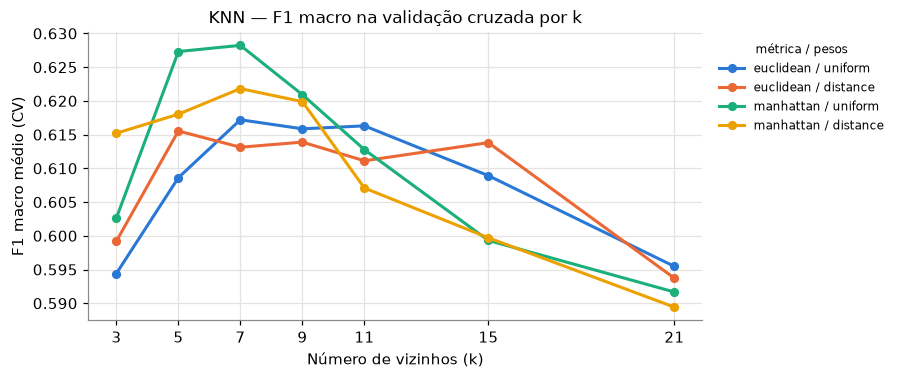

In [22]:
r = pd.DataFrame(gs_knn.cv_results_['params']).rename(columns=lambda c: c.replace('classifier__', ''))
r['f1'] = gs_knn.cv_results_['mean_test_f1_macro']

fig, ax = plt.subplots(figsize=(7.2, 3.4))
combos = [('euclidean', 'uniform'), ('euclidean', 'distance'), ('manhattan', 'uniform'), ('manhattan', 'distance')]
for cor, (metrica, peso) in zip(CORES, combos):
    sub = r[(r['metric'] == metrica) & (r['weights'] == peso)].sort_values('n_neighbors')
    ax.plot(sub['n_neighbors'], sub['f1'], marker='o', markersize=5, linewidth=2, color=cor,
            label=f'{metrica} / {peso}')
ax.set_xlabel('Número de vizinhos (k)')
ax.set_ylabel('F1 macro médio (CV)')
ax.set_title('KNN — F1 macro na validação cruzada por k')
ax.set_xticks(grid_knn['classifier__n_neighbors'])
ax.legend(title='métrica / pesos', fontsize=8, title_fontsize=8, loc='upper left', bbox_to_anchor=(1.01, 1))
salvar_fig(fig, 'knn_f1_por_k')
plt.show()

=== KNN — conjunto de teste ===
              precision    recall  f1-score   support

     Dropout      0.769     0.609     0.680       284
    Enrolled      0.418     0.258     0.319       159
    Graduate      0.714     0.907     0.799       442

    accuracy                          0.695       885
   macro avg      0.634     0.591     0.599       885
weighted avg      0.678     0.695     0.674       885



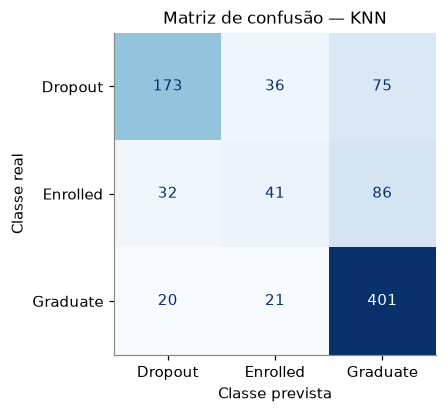

In [23]:
avaliar(gs_knn.best_estimator_, 'KNN');

## 6. Support Vector Machine (SVM)

In [24]:
grid_svm = [
    {
        'classifier__kernel': ['linear'],
        'classifier__C': [0.1, 1, 10],
        'classifier__class_weight': [None, 'balanced'],
    },
    {
        'classifier__kernel': ['rbf'],
        'classifier__C': [0.1, 1, 10],
        'classifier__gamma': ['scale', 'auto'],
        'classifier__class_weight': [None, 'balanced'],
    },
]

gs_svm = buscar(SVC(random_state=RANDOM_STATE), grid_svm)
TABELAS_CV['SVM'] = tabela_cv(gs_svm, 'SVM')
TABELAS_CV['SVM'].head(10)

18 configurações x 5 partições
Melhores parâmetros: C=10, class_weight=balanced, gamma=auto, kernel=rbf
F1 macro (CV): 0.7208


,Modelo,Configuração,Balanceamento,Acurácia (média),Acurácia (dp),Precisão (média),Precisão (dp),Revocação (média),Revocação (dp),F1 macro (média),F1 macro (dp),Tempo de ajuste (s)
0,SVM,"C=10, class_weight=balanced, gamma=auto, kernel=rbf",True,0.7615,0.0068,0.7237,0.0113,0.7280,0.0127,0.7208,0.0095,0.7156
1,SVM,"C=0.1, class_weight=balanced, kernel=linear",True,0.7542,0.0165,0.7192,0.0189,0.7253,0.0168,0.7161,0.0172,0.9573
2,SVM,"C=1, class_weight=balanced, gamma=scale, kernel=rbf",True,0.7553,0.0152,0.7217,0.0204,0.7236,0.0203,0.7158,0.0181,0.9506
3,SVM,"C=1, class_weight=None, kernel=linear",False,0.7790,0.0046,0.7353,0.0102,0.7000,0.0098,0.7102,0.0089,1.3900
4,SVM,"C=10, class_weight=None, gamma=auto, kernel=rbf",False,0.7802,0.0100,0.7321,0.0148,0.7004,0.0171,0.7101,0.0175,0.7410
5,SVM,"C=1, class_weight=balanced, kernel=linear",True,0.7463,0.0135,0.7088,0.0136,0.7143,0.0115,0.7061,0.0131,1.5268
6,SVM,"C=10, class_weight=balanced, kernel=linear",True,0.7437,0.0136,0.7041,0.0122,0.7085,0.0114,0.7017,0.0128,7.6700
7,SVM,"C=10, class_weight=None, kernel=linear",False,0.7728,0.0056,0.7223,0.0128,0.6922,0.0074,0.7009,0.0089,6.6494
8,SVM,"C=0.1, class_weight=None, kernel=linear",False,0.7759,0.0055,0.7342,0.0144,0.6873,0.0103,0.6995,0.0114,0.8383
9,SVM,"C=1, class_weight=balanced, gamma=auto, kernel=rbf",True,0.7389,0.0109,0.7089,0.0156,0.7084,0.0159,0.6990,0.0131,1.1521


=== SVM — conjunto de teste ===
              precision    recall  f1-score   support

     Dropout      0.816     0.687     0.746       284
    Enrolled      0.431     0.629     0.512       159
    Graduate      0.855     0.801     0.827       442

    accuracy                          0.733       885
   macro avg      0.701     0.705     0.695       885
weighted avg      0.766     0.733     0.744       885



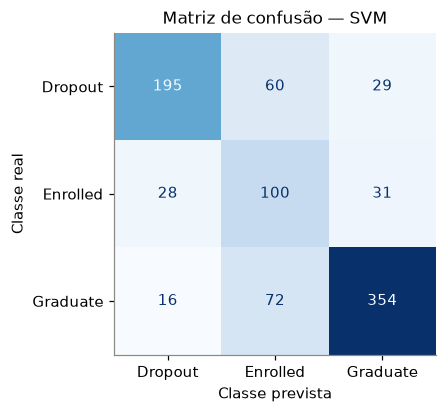

In [25]:
avaliar(gs_svm.best_estimator_, 'SVM');

## 7. Random Forest

In [26]:
grid_rf = {
    'classifier__n_estimators': [100, 300],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_leaf': [1, 5],
    'classifier__class_weight': [None, 'balanced'],
}

gs_rf = buscar(RandomForestClassifier(random_state=RANDOM_STATE), grid_rf)
TABELAS_CV['Random Forest'] = tabela_cv(gs_rf, 'Random Forest')
TABELAS_CV['Random Forest'].head(10)

24 configurações x 5 partições
Melhores parâmetros: class_weight=balanced, max_depth=None, min_samples_leaf=5, n_estimators=300
F1 macro (CV): 0.7213


,Modelo,Configuração,Balanceamento,Acurácia (média),Acurácia (dp),Precisão (média),Precisão (dp),Revocação (média),Revocação (dp),F1 macro (média),F1 macro (dp),Tempo de ajuste (s)
0,Random Forest,"class_weight=balanced, max_depth=None, min_samples_leaf=5, n_estimators=300",True,0.7609,0.0206,0.7253,0.0211,0.7268,0.0241,0.7213,0.0233,2.1470
1,Random Forest,"class_weight=balanced, max_depth=None, min_samples_leaf=1, n_estimators=300",True,0.7725,0.0189,0.7277,0.0234,0.7166,0.0244,0.7205,0.0242,2.8434
2,Random Forest,"class_weight=balanced, max_depth=20, min_samples_leaf=5, n_estimators=300",True,0.7587,0.0201,0.7235,0.0201,0.7250,0.0224,0.7193,0.0222,1.6318
3,Random Forest,"class_weight=balanced, max_depth=20, min_samples_leaf=1, n_estimators=300",True,0.7691,0.0138,0.7255,0.0168,0.7157,0.0183,0.7186,0.0178,2.3246
4,Random Forest,"class_weight=balanced, max_depth=None, min_samples_leaf=5, n_estimators=100",True,0.7564,0.0221,0.7212,0.0216,0.7228,0.0254,0.7170,0.0246,0.8067
5,Random Forest,"class_weight=balanced, max_depth=10, min_samples_leaf=1, n_estimators=300",True,0.7567,0.0210,0.7229,0.0214,0.7223,0.0225,0.7168,0.0223,2.1029
6,Random Forest,"class_weight=balanced, max_depth=20, min_samples_leaf=5, n_estimators=100",True,0.7556,0.0222,0.7206,0.0238,0.7215,0.0266,0.7157,0.0255,0.8043
7,Random Forest,"class_weight=balanced, max_depth=10, min_samples_leaf=1, n_estimators=100",True,0.7533,0.0180,0.7191,0.0188,0.7192,0.0203,0.7132,0.0196,0.7116
8,Random Forest,"class_weight=balanced, max_depth=20, min_samples_leaf=1, n_estimators=100",True,0.7638,0.0209,0.7185,0.0289,0.7109,0.0290,0.7129,0.0287,0.8927
9,Random Forest,"class_weight=balanced, max_depth=10, min_samples_leaf=5, n_estimators=300",True,0.7477,0.0222,0.7179,0.0218,0.7198,0.0230,0.7110,0.0234,1.9564


=== Random Forest — conjunto de teste ===
              precision    recall  f1-score   support

     Dropout      0.833     0.704     0.763       284
    Enrolled      0.441     0.635     0.521       159
    Graduate      0.865     0.814     0.839       442

    accuracy                          0.747       885
   macro avg      0.713     0.718     0.708       885
weighted avg      0.779     0.747     0.758       885



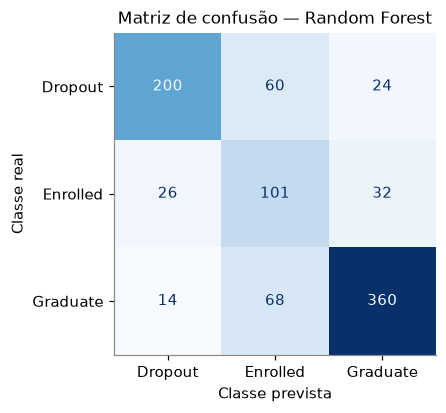

In [27]:
avaliar(gs_rf.best_estimator_, 'Random Forest');

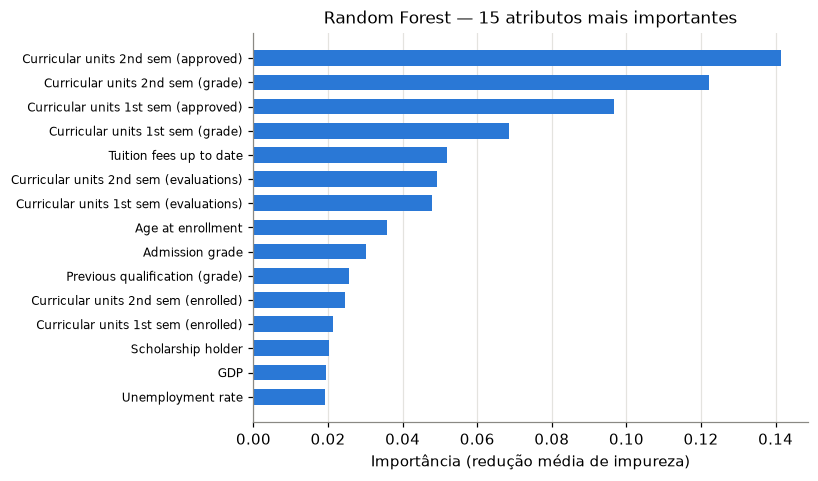

In [28]:
melhor_rf = gs_rf.best_estimator_
nomes = melhor_rf.named_steps['prep'].get_feature_names_out()
nomes = [n.split('__', 1)[1] for n in nomes]
importancias = pd.Series(melhor_rf.named_steps['classifier'].feature_importances_, index=nomes)
top15 = importancias.sort_values(ascending=False).head(15)
top15.rename('Importância').to_csv(RES_DIR / 'importancia_atributos_rf.csv')

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.barh(top15.index[::-1], top15.values[::-1], color=CORES[0], height=0.65)
ax.set_xlabel('Importância (redução média de impureza)')
ax.set_title('Random Forest — 15 atributos mais importantes')
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', labelsize=8)
salvar_fig(fig, 'rf_importancia_atributos')
plt.show()

## 8. XGBoost

O XGBoost não tem `class_weight`, então o balanceamento é feito com `sample_weight` (peso inversamente proporcional à frequência da classe)
passado no `fit`. Como o peso é um parâmetro do treino e não do modelo, a busca é executada **duas vezes**, sem e com pesos, sempre com as mesmas partições.

In [29]:
xgb = XGBClassifier(objective='multi:softprob', eval_metric='mlogloss', tree_method='hist',
                    random_state=RANDOM_STATE, n_jobs=1)

grid_xgb = {
    'classifier__n_estimators': [100, 300],
    'classifier__max_depth': [3, 6],
    'classifier__learning_rate': [0.05, 0.1],
}

print('--- Sem pesos ---')
gs_xgb = buscar(clone(xgb), grid_xgb)

print('\n--- Com sample_weight balanceado ---')
pesos = compute_sample_weight('balanced', y_train)
gs_xgb_bal = buscar(clone(xgb), grid_xgb, classifier__sample_weight=pesos)

--- Sem pesos ---


8 configurações x 5 partições
Melhores parâmetros: learning_rate=0.1, max_depth=3, n_estimators=300
F1 macro (CV): 0.7194

--- Com sample_weight balanceado ---


8 configurações x 5 partições
Melhores parâmetros: learning_rate=0.1, max_depth=3, n_estimators=300
F1 macro (CV): 0.7373


In [30]:
tab_xgb = pd.concat([
    tabela_cv(gs_xgb, 'XGBoost', balanceado=False),
    tabela_cv(gs_xgb_bal, 'XGBoost', balanceado=True),
])
tab_xgb['Configuração'] = np.where(tab_xgb['Balanceamento'],
                                   tab_xgb['Configuração'] + ', sample_weight=balanced',
                                   tab_xgb['Configuração'])
TABELAS_CV['XGBoost'] = tab_xgb.sort_values('F1 macro (média)', ascending=False).reset_index(drop=True)
TABELAS_CV['XGBoost'].to_csv(RES_DIR / 'cv_xgboost.csv', index=False)

gs_xgb_final = gs_xgb_bal if gs_xgb_bal.best_score_ > gs_xgb.best_score_ else gs_xgb
print('Melhor variante:', 'com sample_weight' if gs_xgb_final is gs_xgb_bal else 'sem pesos')
TABELAS_CV['XGBoost'].head(10)

Melhor variante: com sample_weight


,Modelo,Configuração,Balanceamento,Acurácia (média),Acurácia (dp),Precisão (média),Precisão (dp),Revocação (média),Revocação (dp),F1 macro (média),F1 macro (dp),Tempo de ajuste (s)
0,XGBoost,"learning_rate=0.1, max_depth=3, n_estimators=300, sample_weight=balanced",True,0.7765,0.0140,0.7381,0.0130,0.7434,0.0137,0.7373,0.0141,1.4053
1,XGBoost,"learning_rate=0.05, max_depth=3, n_estimators=300, sample_weight=balanced",True,0.7657,0.0155,0.7332,0.0174,0.7396,0.0187,0.7301,0.0180,1.3456
2,XGBoost,"learning_rate=0.1, max_depth=3, n_estimators=100, sample_weight=balanced",True,0.7624,0.0185,0.7309,0.0198,0.7365,0.0227,0.7267,0.0213,0.5145
3,XGBoost,"learning_rate=0.05, max_depth=6, n_estimators=100, sample_weight=balanced",True,0.7609,0.0137,0.7264,0.0160,0.7264,0.0180,0.7209,0.0164,1.1280
4,XGBoost,"learning_rate=0.05, max_depth=6, n_estimators=300, sample_weight=balanced",True,0.7686,0.0183,0.7233,0.0219,0.7202,0.0231,0.7200,0.0226,2.6770
5,XGBoost,"learning_rate=0.1, max_depth=3, n_estimators=300",False,0.7841,0.0109,0.7406,0.0139,0.7092,0.0124,0.7194,0.0131,1.3435
6,XGBoost,"learning_rate=0.1, max_depth=6, n_estimators=100, sample_weight=balanced",True,0.7635,0.0169,0.7223,0.0188,0.7220,0.0216,0.7189,0.0203,1.0359
7,XGBoost,"learning_rate=0.1, max_depth=6, n_estimators=300, sample_weight=balanced",True,0.7686,0.0089,0.7202,0.0117,0.7131,0.0107,0.7158,0.0111,1.5423
8,XGBoost,"learning_rate=0.05, max_depth=3, n_estimators=100, sample_weight=balanced",True,0.7513,0.0157,0.7221,0.0163,0.7238,0.0180,0.7152,0.0170,0.5026
9,XGBoost,"learning_rate=0.1, max_depth=6, n_estimators=100",False,0.7787,0.0074,0.7324,0.0087,0.7015,0.0092,0.7115,0.0093,1.0521


=== XGBoost — conjunto de teste ===
              precision    recall  f1-score   support

     Dropout      0.818     0.697     0.753       284
    Enrolled      0.425     0.623     0.505       159
    Graduate      0.854     0.792     0.822       442

    accuracy                          0.731       885
   macro avg      0.699     0.704     0.693       885
weighted avg      0.765     0.731     0.743       885



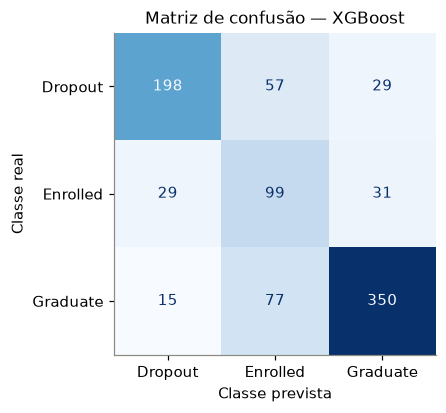

In [31]:
avaliar(gs_xgb_final.best_estimator_, 'XGBoost');

## 9. Comparação dos modelos

### 9.1 Melhor configuração de cada modelo

In [32]:
BUSCAS = {'KNN': gs_knn, 'SVM': gs_svm, 'Random Forest': gs_rf, 'XGBoost': gs_xgb_final}

linhas = []
for nome, gs in BUSCAS.items():
    i = gs.best_index_
    config = formatar_params(gs.best_params_)
    if gs is gs_xgb_bal:
        config += ', sample_weight=balanced'
    linhas.append({
        'Modelo': nome,
        'Melhor configuração': config,
        'F1 macro CV (média)': gs.cv_results_['mean_test_f1_macro'][i],
        'F1 macro CV (dp)': gs.cv_results_['std_test_f1_macro'][i],
        **RESULTADOS_TESTE[nome],
    })
resumo = pd.DataFrame(linhas).set_index('Modelo')
resumo.to_csv(RES_DIR / 'resumo_modelos.csv')
resumo

,Melhor configuração,F1 macro CV (média),F1 macro CV (dp),Acurácia,Precisão (macro),Revocação (macro),F1 (macro),F1 Dropout,F1 Enrolled,F1 Graduate
Modelo,,,,,,,,,,
KNN,"metric=manhattan, n_neighbors=7, weights=uniform",0.6282,0.0137,0.6949,0.6336,0.5914,0.5992,0.6798,0.3191,0.7988
SVM,"C=10, class_weight=balanced, gamma=auto, kernel=rbf",0.7208,0.0095,0.7333,0.7007,0.7055,0.6948,0.7457,0.5115,0.8271
Random Forest,"class_weight=balanced, max_depth=None, min_samples_leaf=5, n_estimators=300",0.7213,0.0233,0.7469,0.7133,0.7180,0.7077,0.7634,0.5206,0.8392
XGBoost,"learning_rate=0.1, max_depth=3, n_estimators=300, sample_weight=balanced",0.7373,0.0141,0.7311,0.6989,0.7039,0.6932,0.7529,0.5051,0.8216


### 9.2 Todas as configurações testadas

In [33]:
todas = pd.concat(TABELAS_CV.values(), ignore_index=True)
todas.to_csv(RES_DIR / 'todas_configuracoes_cv.csv', index=False)

print('Configurações testadas por modelo:')
display(todas['Modelo'].value_counts().reindex(BUSCAS.keys()).rename('Configurações').to_frame())

cols = ['Modelo', 'Configuração', 'Acurácia (média)', 'Precisão (média)', 'Revocação (média)',
        'F1 macro (média)', 'F1 macro (dp)']
todas.groupby('Modelo', sort=False).head(3)[cols]

Configurações testadas por modelo:


,Configurações
Modelo,
KNN,28
SVM,18
Random Forest,24
XGBoost,16


,Modelo,Configuração,Acurácia (média),Precisão (média),Revocação (média),F1 macro (média),F1 macro (dp)
0,KNN,"metric=manhattan, n_neighbors=7, weights=uniform",0.7152,0.6650,0.6176,0.6282,0.0137
1,KNN,"metric=manhattan, n_neighbors=5, weights=uniform",0.7081,0.6487,0.6198,0.6273,0.0218
2,KNN,"metric=manhattan, n_neighbors=7, weights=distance",0.7143,0.6703,0.6104,0.6218,0.0200
28,SVM,"C=10, class_weight=balanced, gamma=auto, kernel=rbf",0.7615,0.7237,0.7280,0.7208,0.0095
29,SVM,"C=0.1, class_weight=balanced, kernel=linear",0.7542,0.7192,0.7253,0.7161,0.0172
30,SVM,"C=1, class_weight=balanced, gamma=scale, kernel=rbf",0.7553,0.7217,0.7236,0.7158,0.0181
46,Random Forest,"class_weight=balanced, max_depth=None, min_samples_leaf=5, n_estimators=300",0.7609,0.7253,0.7268,0.7213,0.0233
47,Random Forest,"class_weight=balanced, max_depth=None, min_samples_leaf=1, n_estimators=300",0.7725,0.7277,0.7166,0.7205,0.0242
48,Random Forest,"class_weight=balanced, max_depth=20, min_samples_leaf=5, n_estimators=300",0.7587,0.7235,0.7250,0.7193,0.0222
70,XGBoost,"learning_rate=0.1, max_depth=3, n_estimators=300, sample_weight=balanced",0.7765,0.7381,0.7434,0.7373,0.0141


In [34]:
# Efeito do balanceamento: melhor configuração (por F1 macro na CV) com e sem class_weight / sample_weight
sem_knn = todas[todas['Modelo'] != 'KNN']
melhores = sem_knn.loc[sem_knn.groupby(['Modelo', 'Balanceamento'], sort=False)['F1 macro (média)'].idxmax()]
efeito = melhores[['Modelo', 'Balanceamento', 'Configuração', 'F1 macro (média)', 'Revocação (média)', 'Acurácia (média)']]
efeito = efeito.assign(Balanceamento=efeito['Balanceamento'].map({True: 'com', False: 'sem'}))
efeito = efeito.sort_values(['Modelo', 'Balanceamento'], ascending=[True, False]).reset_index(drop=True)
efeito.to_csv(RES_DIR / 'efeito_balanceamento.csv', index=False)
efeito

,Modelo,Balanceamento,Configuração,F1 macro (média),Revocação (média),Acurácia (média)
0,Random Forest,sem,"class_weight=None, max_depth=20, min_samples_leaf=1, n_estimators=100",0.6850,0.6750,0.7728
1,Random Forest,com,"class_weight=balanced, max_depth=None, min_samples_leaf=5, n_estimators=300",0.7213,0.7268,0.7609
2,SVM,sem,"C=1, class_weight=None, kernel=linear",0.7102,0.7000,0.7790
3,SVM,com,"C=10, class_weight=balanced, gamma=auto, kernel=rbf",0.7208,0.7280,0.7615
4,XGBoost,sem,"learning_rate=0.1, max_depth=3, n_estimators=300",0.7194,0.7092,0.7841
5,XGBoost,com,"learning_rate=0.1, max_depth=3, n_estimators=300, sample_weight=balanced",0.7373,0.7434,0.7765


### 9.3 Matrizes de confusão e comparação das métricas

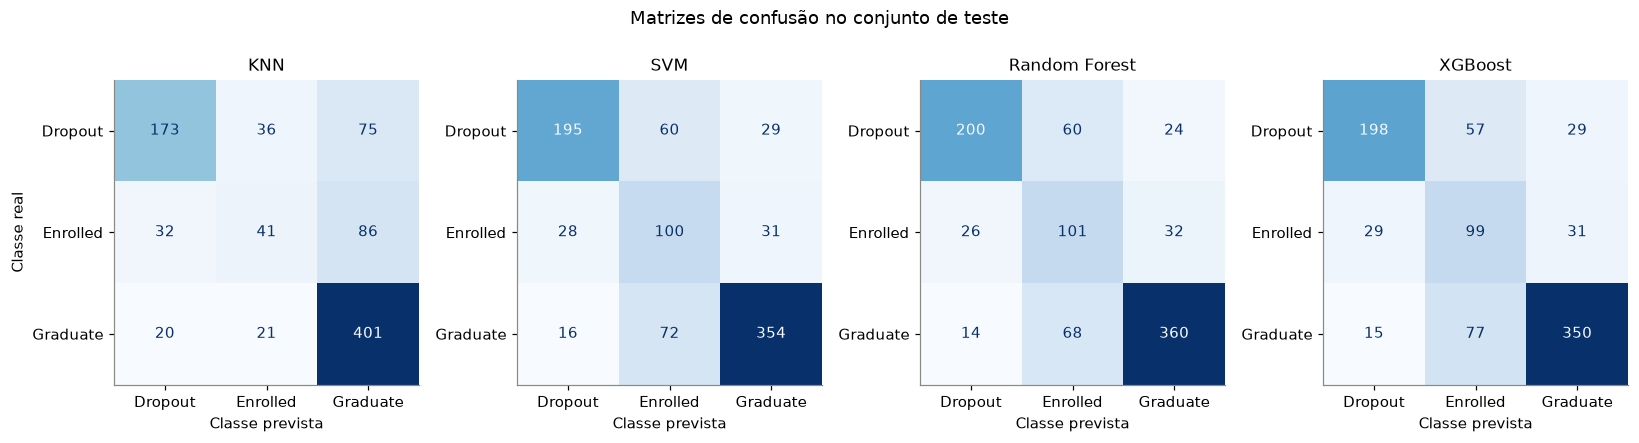

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, (nome, cm) in zip(axes, MATRIZES.items()):
    ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.grid(False)
    ax.set_title(nome)
    ax.set_xlabel('Classe prevista')
    ax.set_ylabel('Classe real' if ax is axes[0] else '')
fig.suptitle('Matrizes de confusão no conjunto de teste', y=1.02)
fig.tight_layout()
salvar_fig(fig, 'matrizes_confusao_todas')
plt.show()

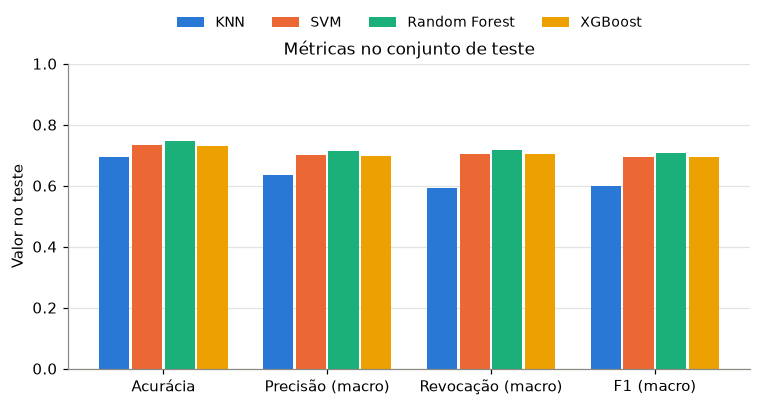

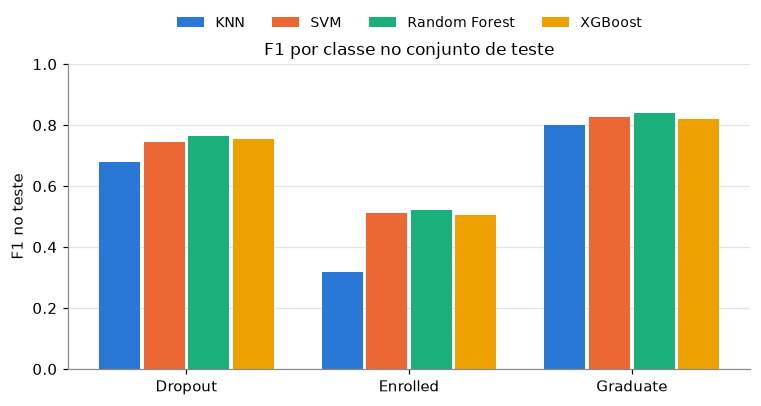

In [36]:
def barras_agrupadas(df, titulo, nome_arquivo, ylabel='Valor no teste'):
    # df: linhas = grupos no eixo x, colunas = modelos (séries).
    fig, ax = plt.subplots(figsize=(8, 3.6))
    n = len(df.columns)
    largura = 0.8 / n
    x = np.arange(len(df.index))
    for i, (modelo, cor) in enumerate(zip(df.columns, CORES)):
        ax.bar(x + (i - (n - 1) / 2) * largura, df[modelo], width=largura * 0.92, color=cor, label=modelo)
    ax.set_xticks(x, df.index)
    ax.set_ylim(0, 1)
    ax.set_ylabel(ylabel)
    ax.set_title(titulo)
    ax.grid(axis='x', visible=False)
    ax.legend(ncol=n, loc='lower center', bbox_to_anchor=(0.5, 1.07), fontsize=9)
    salvar_fig(fig, nome_arquivo)
    plt.show()


metricas_gerais = ['Acurácia', 'Precisão (macro)', 'Revocação (macro)', 'F1 (macro)']
barras_agrupadas(resumo[metricas_gerais].T, 'Métricas no conjunto de teste', 'comparacao_metricas')

f1_classes = resumo[[f'F1 {c}' for c in CLASSES]].T
f1_classes.index = CLASSES
barras_agrupadas(f1_classes, 'F1 por classe no conjunto de teste', 'comparacao_f1_por_classe', ylabel='F1 no teste')

### 9.4 Interpretação dos resultados

**Desempenho geral.**
- Na validação cruzada, o melhor F1 macro foi do **XGBoost com `sample_weight` balanceado** (0,737 ± 0,014), seguido de Random Forest (0,721 ± 0,023) e SVM (0,721 ± 0,010).
- No conjunto de teste, o **Random Forest** teve os melhores valores (F1 macro 0,708, acurácia 0,747), seguido de SVM (0,695) e XGBoost (0,693).
- A ordem entre esses três modelos muda da CV para o teste porque as diferenças entre eles (≈ 0,01–0,02) são da mesma ordem do desvio-padrão entre as partições. Por isso, **não há um vencedor claro entre SVM, Random Forest e XGBoost**: os três têm desempenho equivalente nesta base.
- O **KNN** fica claramente abaixo (F1 macro 0,628 na CV e 0,599 no teste). Ele é o único sem mecanismo de balanceamento e é sensível ao espaço de 119 dimensões gerado pelo *one-hot*, no qual as distâncias ficam menos informativas. Entre as variações do KNN, a distância **Manhattan** com k ≈ 5–7 foi a melhor, e valores de k maiores pioram o F1 macro, porque a classe majoritária passa a dominar a vizinhança.

**Efeito do balanceamento.**
- `class_weight='balanced'` / `sample_weight` **melhorou o F1 macro de todos os modelos em que foi testado**: Random Forest de 0,685 para 0,721, XGBoost de 0,719 para 0,737 e SVM de 0,710 para 0,721.
- O ganho vem da revocação macro: Random Forest de 0,675 para 0,727, XGBoost de 0,709 para 0,743 e SVM de 0,700 para 0,728.
- A troca é uma pequena perda de acurácia (cerca de 1 a 2 pontos), porque o modelo passa a prever mais vezes as classes minoritárias. Para um problema de retenção, em que o objetivo é identificar estudantes em risco, essa troca é favorável.
- Todas as melhores configurações de SVM, Random Forest e XGBoost usam balanceamento.

**Classe *Enrolled*.**
- É a mais difícil para todos os modelos: o F1 vai de 0,32 (KNN) a 0,52 (Random Forest), contra 0,75–0,76 em *Dropout* e 0,82–0,84 em *Graduate*.
- Os estudantes ainda matriculados ficam em uma posição intermediária, entre os que evadem e os que concluem (ver o gráfico 2.6b), e são a classe minoritária (18%).
- Sem balanceamento, o KNN reconhece só 26% dos casos de *Enrolled* e classifica a maioria deles como *Graduate*. Com balanceamento, SVM, Random Forest e XGBoost recuperam cerca de 63% dos casos, ao custo de classificar como *Enrolled* parte dos que concluem (68–77 casos de *Graduate*) e dos que evadem (57–60 casos de *Dropout*).

**Principais confusões.**
- Os erros se concentram entre classes "vizinhas": *Dropout ↔ Enrolled* e *Enrolled ↔ Graduate*.
- A confusão direta entre *Dropout* e *Graduate* é baixa nos três melhores modelos (≈ 40 casos de 885).

**Atributos relevantes.** A importância de atributos do Random Forest mostra que o **desempenho acadêmico nos dois primeiros semestres** (unidades aprovadas e nota média) domina a predição, seguido da **situação financeira** (mensalidades em dia). Isso é coerente com a análise exploratória. As variáveis macroeconômicas (PIB, desemprego, inflação) têm baixa importância.